# Chapter 52: Bank Runs, Collateral Cycles, Crisis Backstops, and Sovereign Links

This notebook reruns four worked examples from the chapter: a collateral cycle that amplifies a cash loss, a run on repo, a Diamond-Dybvig bank run, and a lender of last resort facing a fire sale. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def collateral_capacity(units, price, ltv, cash):
    """Financing capacity = internal funds + ltv x collateral value.

    kiyotaki-moore-collateral-cycle (chapter 52): 12 parcels at 80,000 give 960,000 of collateral and
    0.65 x 960,000 = 624,000 of debt; with 360,000 of cash capacity is 984,000. After the shock
    (cash 270,000, price 68,000): collateral 816,000, debt 530,400, capacity 800,400.
    Returns a dict with collateral, debt and capacity.
    """
    collateral = units * price
    debt = ltv * collateral
    return {"collateral": collateral, "debt": debt, "capacity": cash + debt}


def repo_funding(value, haircut):
    """Repo funding against collateral: (1 - haircut) x value.

    run-on-repo (chapter 52): (1 - 0.04)(240) = 230.4; (1 - 0.12)(240) = 211.2; 0.88(238) = 209.44.
    """
    return (1.0 - haircut) * value


def diamond_dybvig(N, R, lam, c1):
    """Diamond-Dybvig bank with N one-unit deposits, long return R, impatient share lam, early payment c1.

    diamond-dybvig-bank-run-mechanism (chapter 52): N 80, R 1.40, lam 0.20, c1 1.10. Interrupted
    16 x 1.10 = 17.6, invested 62.4, date-2 output 87.36, c2 = 87.36 / 64 = 1.365, total 104.96;
    in a run the bank makes 72 full payments (79.2) with 0.8 left, and 24.96 is lost.
    """
    early = lam * N
    interrupted = early * c1
    invested = N - interrupted
    output = invested * R
    late = N - early
    c2 = output / late
    payments = math.floor(N / c1 + 1e-9)
    total = interrupted + output
    return {"early": early, "late": late, "interrupted": interrupted, "invested": invested, "output": output,
            "c2": c2, "total": total, "run_total": float(N), "loss": total - N, "payments": payments,
            "paid": payments * c1, "residue": N - payments * c1,
            "feasibility": lam * c1 + (1 - lam) * c2 / R}


def fire_sale(cash, loans, deposits, run, price):
    """Meet a run by selling loans at a fire-sale price per dollar of normal value.

    lender-of-last-resort (chapter 52): cash 18, loans 90, deposits 80, run 38, price 0.65. Equity
    18 + 90 - 80 = 28; gap 20; loans sold 20 / 0.65 = 30.769; kept 59.231; equity 59.231 - 42 = 17.231;
    value destroyed 10.769.
    """
    equity0 = cash + loans - deposits
    gap = max(0.0, run - cash)
    sold = gap / price
    kept = loans - sold
    remaining = deposits - run
    equity = kept + max(0.0, cash - run) - remaining
    return {"equity0": equity0, "gap": gap, "sold": sold, "kept": kept, "remaining": remaining,
            "equity": equity, "destroyed": equity0 - equity}


def lolr_advance(gap, haircut, rate, days):
    """Central bank advance against collateral: pledged = gap / (1 - haircut), simple interest gap x rate x days/365.

    lender-of-last-resort (chapter 52): 20 / (1 - 0.20) = 25; 20(0.08)(60/365) = 0.263.
    """
    return {"collateral": gap / (1.0 - haircut), "interest": gap * rate * days / 365.0}


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(collateral_capacity=collateral_capacity, repo_funding=repo_funding, diamond_dybvig=diamond_dybvig, fire_sale=fire_sale, lolr_advance=lolr_advance)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'kiyotaki-moore-collateral-cycle': {'units': 12,
                                     'p0': 80000,
                                     'p1': 68000,
                                     'ltv': 0.65,
                                     'cash': 360000,
                                     'shock': 90000,
                                     'collateral0': 960000,
                                     'debt0': 624000,
                                     'capacity0': 984000,
                                     'capacity_no_reprice': 894000,
                                     'collateral1': 816000,
                                     'debt1': 530400,
                                     'capacity1': 800400,
                                     'decline': 183600,
                                     'reprice': 93600},
 'run-on-repo': {'value': 240,
                 'h0': 0.04,
                 'h1': 0.12,
                 'value1': 238,
                 'funding0': 230.4,
                 'equity': 9.6,
                 'leverage': 25,
                 'funding_h1': 211.2,
                 'funding1': 209.44,
                 'gap': 20.96,
                 'haircut_part': 19.2,
                 'price_part': 1.76,
                 'market_equity': 7.6},
 'diamond-dybvig-bank-run-mechanism': {'N': 80,
                                       'R': 1.4,
                                       'lam': 0.2,
                                       'c1': 1.1,
                                       'interrupted': 17.6,
                                       'invested': 62.4,
                                       'output': 87.36,
                                       'c2': 1.365,
                                       'total': 104.96,
                                       'run_total': 80,
                                       'loss': 24.96,
                                       'payments': 72,
                                       'paid': 79.2,
                                       'residue': 0.8},
 'lender-of-last-resort': {'cash': 18,
                           'loans': 90,
                           'deposits': 80,
                           'run': 38,
                           'price': 0.65,
                           'haircut': 0.2,
                           'rate': 0.08,
                           'days': 60,
                           'equity0': 28,
                           'gap': 20,
                           'sold': 30.769,
                           'kept': 59.231,
                           'equity_fire': 17.231,
                           'destroyed': 10.769,
                           'collateral': 25,
                           'equity_facility': 28,
                           'interest': 0.263},
 'constructed': {'kiyotaki-moore-collateral-cycle': {'p1': [62000, 74000], 'ltv': [0.5, 0.8]},
                 'run-on-repo': {'h': [0.08, 0.2], 'a1': [230]},
                 'diamond-dybvig-bank-run-mechanism': {'c1': [1.0, 1.2], 'lam': [0.1, 0.3]},
                 'lender-of-last-resort': {'f': [0.5, 0.8], 'run': [28, 48]}}}


def collateral_picture(p1=68000, ltv=0.65):
    b = BV["kiyotaki-moore-collateral-cycle"]
    units, p0, cash, shock = b["units"], b["p0"], b["cash"], b["shock"]
    base = finance.collateral_capacity(units, p0, ltv, cash)
    after = finance.collateral_capacity(units, p1, ltv, cash - shock)
    reprice = base["debt"] - after["debt"]
    decline = base["capacity"] - after["capacity"]
    fig, ax = new_figure()
    xs = np.arange(2)
    cashes = [cash, cash - shock]
    debts = [base["debt"], after["debt"]]
    ax.bar(xs, cashes, width=0.5, color=PALETTE["gold"], label="internal funds")
    ax.bar(xs, debts, bottom=cashes, width=0.5, color=PALETTE["navy"], label="debt against collateral")
    ax.bar([1], [shock], bottom=[after["capacity"]], width=0.5, color=PALETTE["grey"], alpha=0.5,
           label="lost to the cash shock")
    if reprice > 0:
        ax.bar([1], [reprice], bottom=[after["capacity"] + shock], width=0.5, color=PALETTE["terracotta"], alpha=0.6,
               label="lost to repricing")
    label(ax, 0, base["capacity"], num(base["capacity"], 0), dx=0, dy=3, ha="center")
    label(ax, 1, after["capacity"], f"{num(after['capacity'], 0)}", dx=40, dy=0, ha="left", va="center")
    ax.set_xticks(xs, ["Before the shock", "After the shock"])
    ax.set_xlim(-0.6, 2.2)
    ax.set_ylim(0, 1_750_000)
    ax.ticklabel_format(style="plain", axis="y")
    ax.legend(loc="upper right", frameon=False)
    ax.set_ylabel("Financing capacity (dollars)")
    ax.set_xlabel("Firm with 12 parcels")
    bigger = "larger than" if reprice > shock else ("equal to" if reprice == shock else "smaller than")
    metrics = {"Capacity before": money(base["capacity"], 0), "Capacity after": money(after["capacity"], 0),
               "Cash-loss part": money(shock, 0), "Repricing part": money(reprice, 0),
               "Total decline": money(decline, 0)}
    interp = (f"Before: {num(cash, 0)} + {num(ltv, 2)} x 12 x {num(p0, 0)} = {num(cash, 0)} + {num(base['debt'], 0)} = "
              f"{num(base['capacity'], 0)}. After: {num(cash - shock, 0)} + {num(ltv, 2)} x 12 x {num(p1, 0)} = "
              f"{num(cash - shock, 0)} + {num(after['debt'], 0)} = {num(after['capacity'], 0)}. Capacity falls "
              f"{num(decline, 0)}: {num(shock, 0)} from the cash loss and {num(reprice, 0)} from repricing, "
              + (f"so the repricing loss is {bigger} the cash loss." if reprice > 0 else
                 "so with the price held there is no repricing loss.")
              )
    steps = [f"Debt before = {num(ltv, 2)} x 12 x {num(p0, 0)} = {num(base['debt'], 0)}",
             f"Capacity before = {num(cash, 0)} + {num(base['debt'], 0)} = {num(base['capacity'], 0)}",
             f"Debt after = {num(ltv, 2)} x 12 x {num(p1, 0)} = {num(after['debt'], 0)}",
             f"Capacity after = {num(cash - shock, 0)} + {num(after['debt'], 0)} = {num(after['capacity'], 0)}",
             f"Repricing part = {num(base['debt'], 0)} - {num(after['debt'], 0)} = {num(reprice, 0)}"]
    alt = (f"Stacked bars of internal funds and collateral debt. Capacity falls from {num(base['capacity'], 0)} to "
           f"{num(after['capacity'], 0)}: {num(shock, 0)} from the cash shock and {num(reprice, 0)} from repricing.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def repo_picture(h=0.12, a1=238):
    b = BV["run-on-repo"]
    value, h0 = b["value"], b["h0"]
    f0 = finance.repo_funding(value, h0)
    f_h = finance.repo_funding(value, h)
    f1 = finance.repo_funding(a1, h)
    gap = f0 - f1
    hair = f0 - f_h
    price = f_h - f1
    equity = a1 - f0
    fig, ax = new_figure()
    xs = np.arange(3)
    ax.bar(xs[:2], [f0, f1], width=0.55, color=[PALETTE["navy"], PALETTE["teal"]])
    if hair > 0:
        ax.bar([1], [hair], bottom=[f1 + price], width=0.55, color=PALETTE["terracotta"], alpha=0.6, label="haircut part")
    if price > 0:
        ax.bar([1], [price], bottom=[f1], width=0.55, color=PALETTE["gold"], alpha=0.7, label="markdown part")
    ax.bar([2], [equity], width=0.55, color=PALETTE["olive"])
    label(ax, 0, f0, num(f0, 2), dx=0, dy=3, ha="center")
    label(ax, 1, f1, num(f1, 2), dx=0, dy=-4, ha="center", va="top")
    label(ax, 2, equity, num(equity, 2), dx=0, dy=3, ha="center")
    ax.set_xticks(xs, ["Old repo", "New funding", "Market equity"])
    ax.set_ylim(-12 if equity < 0 else 0, 300)
    if equity < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    if hair > 0 or price > 0:
        ax.legend(loc="upper right", frameon=False)
    ax.set_ylabel("Million dollars")
    ax.set_xlabel("Dealer at rollover")
    metrics = {"Old repo": num(f0, 2), "New funding": num(f1, 2), "Cash to replace": num(gap, 2),
               "Haircut part": num(hair, 2), "Markdown part": num(price, 2), "Market equity": num(equity, 2),
               "Solvent at market value": "yes" if equity > 0 else "no"}
    if gap > 1e-9:
        tail = (f"The dealer must replace {num(gap, 2)} million in cash while its market equity is still "
                f"{num(equity, 2)} million: a payment problem before insolvency." if equity > 0 else
                f"The dealer must replace {num(gap, 2)} million in cash, and with market equity of {num(equity, 2)} "
                f"million it is also insolvent at the marked-down value.")
    else:
        tail = "No cash needs replacing: the old loan rolls over in full."
    interp = (f"New funding is (1 - {num(h, 2)}) x {num(a1, 0)} = {num(f1, 2)} against the old (1 - 0.04) x 240 = "
              f"{num(f0, 2)}, a gap of {num(f0, 2)} - {num(f1, 2)} = {num(gap, 2)}. The haircut accounts for "
              f"{num(hair, 2)} and the markdown for {num(1 - h, 2)} x {num(value - a1, 0)} = {num(price, 2)}. {tail}")
    steps = [f"Old repo = 0.96 x 240 = {num(f0, 2)}",
             f"New funding = {num(1 - h, 2)} x {num(a1, 0)} = {num(f1, 2)}",
             f"Gap = {num(f0, 2)} - {num(f1, 2)} = {num(gap, 2)}",
             f"Haircut part = {num(f0, 2)} - {num(1 - h, 2)} x 240 = {num(f0, 2)} - {num(f_h, 2)} = {num(hair, 2)}",
             f"Markdown part = {num(1 - h, 2)} x {num(value - a1, 0)} = {num(price, 2)}",
             f"Market equity = {num(a1, 0)} - {num(f0, 2)} = {num(equity, 2)}"]
    alt = (f"Bars of the old repo {num(f0, 2)} million, new funding {num(f1, 2)} million and market equity "
           f"{num(equity, 2)} million; the gap of {num(gap, 2)} splits into haircut {num(hair, 2)} and markdown {num(price, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def dd_picture(c1=1.10, lam=0.20):
    b = BV["diamond-dybvig-bank-run-mechanism"]
    N, R = b["N"], b["R"]
    d = finance.diamond_dybvig(N, R, lam, c1)
    fig, ax = new_figure()
    xs = np.arange(2)
    w = 0.36
    ax.bar(xs - w / 2, [c1, c1], width=w, color=PALETTE["gold"], label="paid early (c1)")
    ax.bar([0 + w / 2], [d["c2"]], width=w, color=PALETTE["teal"], label="paid late (c2), no run")
    ax.bar([1 + w / 2], [0.0], width=w, color=PALETTE["terracotta"])
    hline(ax, c1, None, col="grey")
    label(ax, -w / 2, c1, num(c1, 2), dx=0, dy=3, ha="center")
    label(ax, w / 2, d["c2"], num(d["c2"], 3), dx=0, dy=3, ha="center")
    label(ax, 1 - w / 2, c1, f"first {d['payments']} paid", dx=0, dy=3, ha="center")
    rest = f"rest share {num(d['residue'], 2)}" if d["payments"] < N else "no one left"
    label(ax, 1 + w / 2, 0, rest, dx=0, dy=3, ha="center")
    ax.set_xticks(xs, [f"No run: total {num(d['total'], 2)}", f"Run: total {num(N, 0)}"])
    ax.set_ylim(0, 2.0)
    ax.set_xlim(-0.6, 1.6)
    ax.legend(loc="upper right", frameon=False)
    ax.set_ylabel("Payment per depositor")
    ax.set_xlabel("Outcome")
    wait = d["c2"] > c1
    metrics = {"Interrupted for early claims": num(d["interrupted"], 2), "c2": num(d["c2"], 3),
               "Total consumption, no run": num(d["total"], 2), "Total in a run": num(N, 0),
               "Loss from a run": num(d["loss"], 2), "Full payments in a run": str(d["payments"]),
               "Left after full payments": num(d["residue"], 2)}
    early = d["early"]
    interp = (f"{num(early, 0)} impatient depositors take {num(early, 0)} x {num(c1, 2)} = {num(d['interrupted'], 2)}, "
              f"leaving {num(d['invested'], 2)} invested, which pays {num(d['invested'], 2)} x 1.40 = "
              f"{num(d['output'], 2)}. Shared among {num(d['late'], 0)} patient depositors, c2 = {num(d['output'], 2)} / "
              f"{num(d['late'], 0)} = {num(d['c2'], 3)}, "
              + ("above c1, so a patient depositor waits if others wait. " if wait else
                 "not above c1, so even without a panic patient depositors would rather withdraw early. ")
              + (f"In a run the bank can pay only {d['payments']} claims of {num(c1, 2)} in full ({num(d['paid'], 2)}), "
                 if d["payments"] < N else
                 f"In a run all {d['payments']} claims of {num(c1, 2)} are paid in full ({num(d['paid'], 2)}), but "
                 f"nothing is left to wait for, ")
              + f"and total consumption falls from {num(d['total'], 2)} to 80, a loss of {num(d['loss'], 2)}.")
    steps = [f"Interrupted = {num(early, 0)} x {num(c1, 2)} = {num(d['interrupted'], 2)}",
             f"Date-2 output = (80 - {num(d['interrupted'], 2)}) x 1.40 = {num(d['output'], 2)}",
             f"c2 = {num(d['output'], 2)} / {num(d['late'], 0)} = {num(d['c2'], 3)}",
             f"No-run total = {num(d['interrupted'], 2)} + {num(d['output'], 2)} = {num(d['total'], 2)}",
             f"Run: {d['payments']} x {num(c1, 2)} = {num(d['paid'], 2)}, leaving {num(d['residue'], 2)}",
             f"Loss = {num(d['total'], 2)} - 80 = {num(d['loss'], 2)}"]
    alt = (f"Payments per depositor. Without a run, early claimants get {num(c1, 2)} and patient ones {num(d['c2'], 3)}. "
           + (f"In a run the first {d['payments']} get {num(c1, 2)} and the rest share {num(d['residue'], 2)}."
              if d["payments"] < N else f"In a run all {d['payments']} get {num(c1, 2)} and nothing is left."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def lolr_picture(f=0.65, run=38):
    b = BV["lender-of-last-resort"]
    cash, loans, deposits = b["cash"], b["loans"], b["deposits"]
    fs = finance.fire_sale(cash, loans, deposits, run, f)
    adv = finance.lolr_advance(fs["gap"], b["haircut"], b["rate"], b["days"])
    eq_fac = loans - fs["remaining"] - fs["gap"]
    fig, ax = new_figure()
    bar_compare(ax, ["Before the run", "Fire sale", "Central bank advance", "Collateral pledged"],
                [fs["equity0"], fs["equity"], eq_fac, adv["collateral"]],
                colors=["grey", "terracotta", "teal", "navy"],
                value_labels=[num(fs["equity0"], 3), num(fs["equity"], 3), num(eq_fac, 3), num(adv["collateral"], 3)],
                ylabel="Million dollars", xlabel="Equity under each response, and collateral for the advance")
    ax.set_ylim(min(0.0, fs["equity"]) - (8 if fs["equity"] < 0 else 0), 75)
    metrics = {"Cash gap": num(fs["gap"], 0), "Loans sold": num(fs["sold"], 3), "Equity after fire sale": num(fs["equity"], 3),
               "Value destroyed": num(fs["destroyed"], 3),
               "Solvent after fire sale": "yes" if fs["equity"] > 0 else "no", "Collateral pledged": num(adv["collateral"], 3),
               "Equity with the facility": num(eq_fac, 3), "Interest, 60 days": num(adv["interest"], 3)}
    interp = (f"The run of {num(run, 0)} takes the 18 of cash and leaves a gap of {num(fs['gap'], 0)}. Selling loans at "
              f"{num(f, 2)} needs {num(fs['gap'], 0)} / {num(f, 2)} = {num(fs['sold'], 3)} of loans, leaving "
              f"{num(fs['kept'], 3)} against {num(fs['remaining'], 0)} of deposits: equity {num(fs['kept'], 3)} - "
              f"{num(fs['remaining'], 0)} = {num(fs['equity'], 3)}, so {num(fs['destroyed'], 3)} is destroyed"
              f"{' and the fire sale leaves the bank insolvent' if fs['equity'] < 0 else ''}. With "
              f"the facility the bank pledges {num(fs['gap'], 0)} / 0.80 = {num(adv['collateral'], 3)} and keeps equity "
              f"90 - {num(fs['remaining'], 0)} - {num(fs['gap'], 0)} = {num(eq_fac, 0)} before interest of "
              f"{num(fs['gap'], 0)} x 0.08 x 60 / 365 = {num(adv['interest'], 3)}.")
    steps = [f"Gap = {num(run, 0)} - 18 = {num(fs['gap'], 0)}",
             f"Loans sold = {num(fs['gap'], 0)} / {num(f, 2)} = {num(fs['sold'], 3)}",
             f"Fire-sale equity = (90 - {num(fs['sold'], 3)}) - {num(fs['remaining'], 0)} = {num(fs['equity'], 3)}",
             f"Destroyed = 28 - {num(fs['equity'], 3) if fs['equity'] >= 0 else '(' + num(fs['equity'], 3) + ')'} = {num(fs['destroyed'], 3)}",
             f"Collateral = {num(fs['gap'], 0)} / (1 - 0.20) = {num(adv['collateral'], 3)}",
             f"Facility equity = 90 - {num(fs['remaining'], 0)} - {num(fs['gap'], 0)} = {num(eq_fac, 0)}",
             f"Interest = {num(fs['gap'], 0)} x 0.08 x 60 / 365 = {num(adv['interest'], 3)}"]
    alt = (f"Bars of bank equity: 28 before the run, {num(fs['equity'], 3)} after a fire sale at {num(f, 2)}, "
           f"{num(eq_fac, 0)} with a central bank advance backed by {num(adv['collateral'], 3)} of collateral.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Kiyotaki-Moore collateral cycle: collateral prices amplify a cash loss

A firm owns 12 parcels at \$80,000, may borrow 65 percent of their value and has \$360,000 of internal funds. A shock removes \$90,000 of cash and the parcel price falls to \$68,000.

$$0.65(960{,}000)=624{,}000, \qquad 0.65(816{,}000)=530{,}400$$

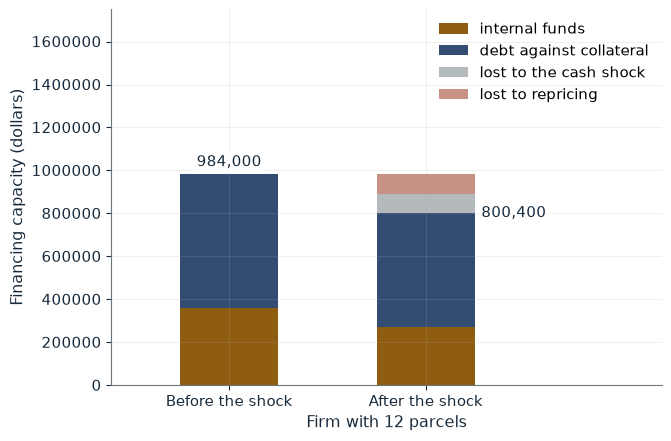

Capacity before  $984,000
Capacity after   $800,400
Cash-loss part   $90,000
Repricing part   $93,600
Total decline    $183,600

Worked steps:
  1. Debt before = 0.65 x 12 x 80,000 = 624,000
  2. Capacity before = 360,000 + 624,000 = 984,000
  3. Debt after = 0.65 x 12 x 68,000 = 530,400
  4. Capacity after = 270,000 + 530,400 = 800,400
  5. Repricing part = 624,000 - 530,400 = 93,600

Before: 360,000 + 0.65 x 12 x 80,000 = 360,000 + 624,000 = 984,000. After: 270,000 + 0.65 x 12 x 68,000 = 270,000 + 530,400 = 800,400. Capacity falls 183,600: 90,000 from the cash loss and 93,600 from repricing, so the repricing loss is larger than the cash loss.


In [2]:
show(collateral_picture(p1=68000, ltv=0.65))

Change one input, `p1`, and hold the others at the book's values:

In [3]:
sweep(collateral_picture, 'p1', [62000, 68000, 74000, 80000], {'ltv': 0.65}, ['Capacity after', 'Repricing part', 'Total decline'])

p1 | Capacity after | Repricing part | Total decline
62000 | $753,600 | $140,400 | $230,400
68000 | $800,400 | $93,600 | $183,600
74000 | $847,200 | $46,800 | $136,800
80000 | $894,000 | $0 | $90,000


Capacity falls from 984,000 to 800,400: 90,000 from the cash loss and 93,600 from repricing. If the price held at 80,000 capacity would be 894,000.

## 2. Run on repo: haircuts drain a dealer

A dealer funds 240 million of collateral at a 4 percent haircut. At rollover the haircut is 12 percent and the collateral is worth 238 million.

$$(1-0.04)(240)=230.4, \qquad 0.88(238)=209.44, \qquad 230.4-209.44=20.96$$

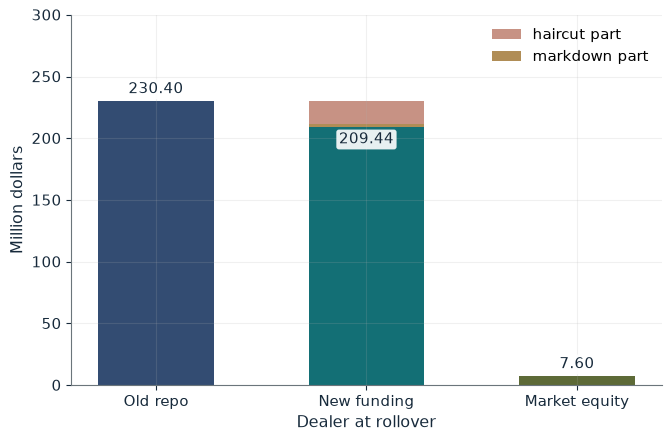

Old repo                 230.40
New funding              209.44
Cash to replace          20.96
Haircut part             19.20
Markdown part            1.76
Market equity            7.60
Solvent at market value  yes

Worked steps:
  1. Old repo = 0.96 x 240 = 230.40
  2. New funding = 0.88 x 238 = 209.44
  3. Gap = 230.40 - 209.44 = 20.96
  4. Haircut part = 230.40 - 0.88 x 240 = 230.40 - 211.20 = 19.20
  5. Markdown part = 0.88 x 2 = 1.76
  6. Market equity = 238 - 230.40 = 7.60

New funding is (1 - 0.12) x 238 = 209.44 against the old (1 - 0.04) x 240 = 230.40, a gap of 230.40 - 209.44 = 20.96. The haircut accounts for 19.20 and the markdown for 0.88 x 2 = 1.76. The dealer must replace 20.96 million in cash while its market equity is still 7.60 million: a payment problem before insolvency.


In [4]:
show(repo_picture(h=0.12, a1=238))

Change one input, `h`, and hold the others at the book's values:

In [5]:
sweep(repo_picture, 'h', [0.04, 0.08, 0.12, 0.2], {'a1': 238}, ['New funding', 'Cash to replace', 'Haircut part', 'Markdown part'])

h | New funding | Cash to replace | Haircut part | Markdown part
0.04 | 228.48 | 1.92 | 0.00 | 1.92
0.08 | 218.96 | 11.44 | 9.60 | 1.84
0.12 | 209.44 | 20.96 | 19.20 | 1.76
0.2 | 190.40 | 40.00 | 38.40 | 1.60


The dealer must find 20.96 million: 19.2 from the haircut and 1.76 from the markdown, while its market equity is still 7.6 million. At a value of 230 million equity turns negative.

## 3. Diamond-Dybvig: a run on a sound bank

80 depositors, $R=1.40$, $\lambda=0.20$, $c_1=1.10$.

$$c_2=\frac{87.36}{64}=1.365, \qquad 0.20(1.10)+\frac{0.80(1.365)}{1.40}=0.22+0.78=1$$

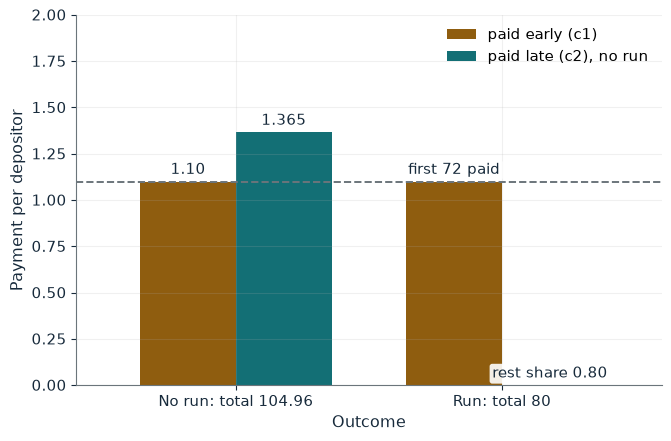

Interrupted for early claims  17.60
c2                            1.365
Total consumption, no run     104.96
Total in a run                80
Loss from a run               24.96
Full payments in a run        72
Left after full payments      0.80

Worked steps:
  1. Interrupted = 16 x 1.10 = 17.60
  2. Date-2 output = (80 - 17.60) x 1.40 = 87.36
  3. c2 = 87.36 / 64 = 1.365
  4. No-run total = 17.60 + 87.36 = 104.96
  5. Run: 72 x 1.10 = 79.20, leaving 0.80
  6. Loss = 104.96 - 80 = 24.96

16 impatient depositors take 16 x 1.10 = 17.60, leaving 62.40 invested, which pays 62.40 x 1.40 = 87.36. Shared among 64 patient depositors, c2 = 87.36 / 64 = 1.365, above c1, so a patient depositor waits if others wait. In a run the bank can pay only 72 claims of 1.10 in full (79.20), and total consumption falls from 104.96 to 80, a loss of 24.96.


In [6]:
show(dd_picture(c1=1.10, lam=0.20))

Change one input, `c1`, and hold the others at the book's values:

In [7]:
sweep(dd_picture, 'c1', [1.0, 1.1, 1.2], {'lam': 0.2}, ['c2', 'Total consumption, no run', 'Full payments in a run', 'Loss from a run'])

c1 | c2 | Total consumption, no run | Full payments in a run | Loss from a run
1.0 | 1.400 | 105.60 | 80 | 25.60
1.1 | 1.365 | 104.96 | 72 | 24.96
1.2 | 1.330 | 104.32 | 66 | 24.32


Waiting pays when others wait (1.365 is above 1.10), but in a run the bank pays only 72 claims in full and 24.96 units of consumption are lost.

## 4. Lender of last resort: fire sale or central bank window

Cash 18, loans 90, deposits 80; a run of 38 leaves a gap of 20.

$$\frac{20}{0.65}\approx30.769, \qquad \frac{20}{1-0.20}=25, \qquad 20(0.08)\left(\frac{60}{365}\right)\approx0.263$$

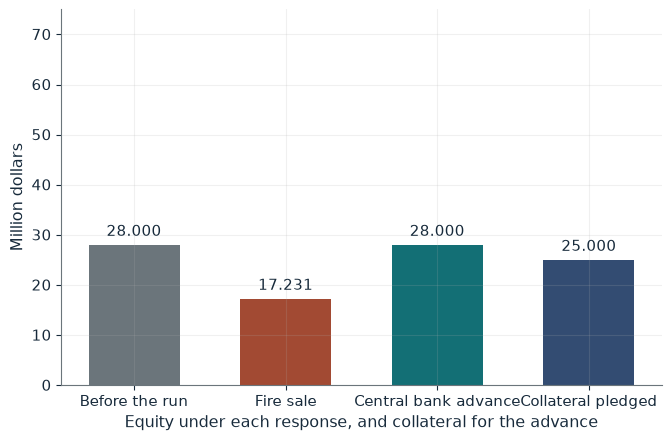

Cash gap                  20
Loans sold                30.769
Equity after fire sale    17.231
Value destroyed           10.769
Solvent after fire sale   yes
Collateral pledged        25.000
Equity with the facility  28.000
Interest, 60 days         0.263

Worked steps:
  1. Gap = 38 - 18 = 20
  2. Loans sold = 20 / 0.65 = 30.769
  3. Fire-sale equity = (90 - 30.769) - 42 = 17.231
  4. Destroyed = 28 - 17.231 = 10.769
  5. Collateral = 20 / (1 - 0.20) = 25.000
  6. Facility equity = 90 - 42 - 20 = 28
  7. Interest = 20 x 0.08 x 60 / 365 = 0.263

The run of 38 takes the 18 of cash and leaves a gap of 20. Selling loans at 0.65 needs 20 / 0.65 = 30.769 of loans, leaving 59.231 against 42 of deposits: equity 59.231 - 42 = 17.231, so 10.769 is destroyed. With the facility the bank pledges 20 / 0.80 = 25.000 and keeps equity 90 - 42 - 20 = 28 before interest of 20 x 0.08 x 60 / 365 = 0.263.


In [8]:
show(lolr_picture(f=0.65, run=38))

Change one input, `f`, and hold the others at the book's values:

In [9]:
sweep(lolr_picture, 'f', [0.5, 0.65, 0.8], {'run': 38}, ['Loans sold', 'Equity after fire sale', 'Value destroyed'])

f | Loans sold | Equity after fire sale | Value destroyed
0.5 | 40.000 | 8.000 | 20.000
0.65 | 30.769 | 17.231 | 10.769
0.8 | 25.000 | 23.000 | 5.000


A fire sale at 65 cents destroys 10.769 million of equity; a facility lending against 25 million of collateral keeps equity at 28 before about 0.263 million of interest.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

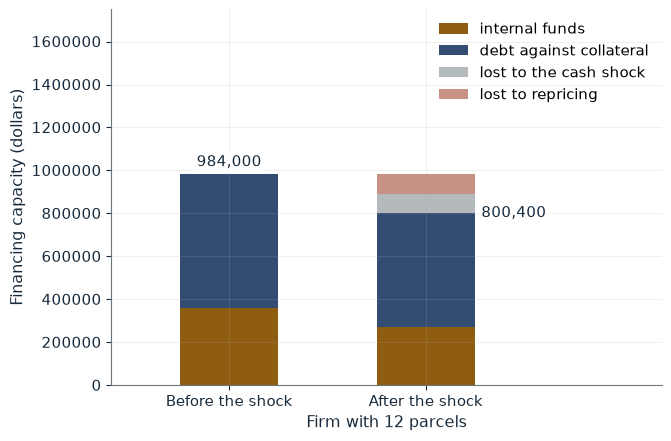

Capacity before  $984,000
Capacity after   $800,400
Cash-loss part   $90,000
Repricing part   $93,600
Total decline    $183,600

Worked steps:
  1. Debt before = 0.65 x 12 x 80,000 = 624,000
  2. Capacity before = 360,000 + 624,000 = 984,000
  3. Debt after = 0.65 x 12 x 68,000 = 530,400
  4. Capacity after = 270,000 + 530,400 = 800,400
  5. Repricing part = 624,000 - 530,400 = 93,600

Before: 360,000 + 0.65 x 12 x 80,000 = 360,000 + 624,000 = 984,000. After: 270,000 + 0.65 x 12 x 68,000 = 270,000 + 530,400 = 800,400. Capacity falls 183,600: 90,000 from the cash loss and 93,600 from repricing, so the repricing loss is larger than the cash loss.


In [10]:
show(collateral_picture(p1=68000, ltv=0.65))

## Practice

**1.** If buyers held the parcel price at \$80,000, what is the firm's capacity after the \$90,000 cash shock?

<details><summary>Answer</summary>

270,000 + 0.65 x 960,000 = 270,000 + 624,000 = 894,000 dollars.

</details>

**2.** In a run with c1 = 1.10 and 80 units of assets, how many full payments can the bank make?

<details><summary>Answer</summary>

80 / 1.10 = 72.7, so 72 payments of 1.10 = 79.2, leaving 0.8.

</details>

**3.** With a 20 percent haircut, how much collateral backs a 20 million advance?

<details><summary>Answer</summary>

20 / (1 - 0.20) = 25 million.

</details>